In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
path = "/home/kushal/caiman_data/example_movies/demoMovie.tif"

In [112]:
movie = tifffile.imread(path)[:, ::2, ::2]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
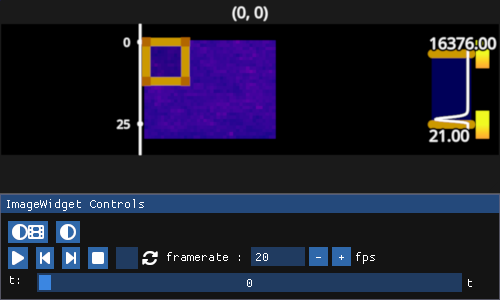

In [113]:
iw_movie = fpl.ImageWidget(movie)
rs = iw_movie.managed_graphics[0].add_rectangle_selector()
iw_movie.show()

In [116]:
row_ixs, col_ixs = rs.get_selected_indices()
row_slice = slice(row_ixs[0], row_ixs[-1] + 1)
col_slice = slice(col_ixs[0], col_ixs[-1] + 1)
movie_sub = movie[:, row_slice, col_slice]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
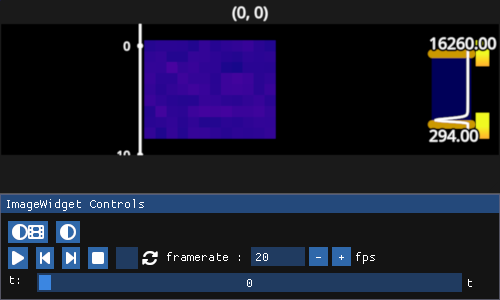

In [117]:
iw_sub = fpl.ImageWidget(movie_sub)
iw_sub.show()

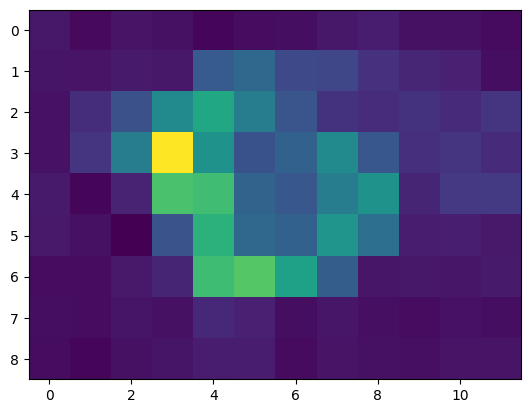

In [283]:
plt.imshow(movie_sub.max(axis=0))

In [118]:
from skophys.preprocessing import UnVectorizer, Vectorizer

In [119]:
unvec = UnVectorizer(movie_sub.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie_sub)

In [120]:
X.shape

(108, 2000)

In [121]:
n_pixels = X.shape[0]

In [135]:
lag = 4

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * 2], X[i, lag * 2 - 1:]))

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [142]:
H.shape

(864, 1993)

In [143]:
304*lag*2

2432

In [144]:
mu0 = np.mean(H[:lag * n_pixels])
mu1 = np.mean(H[lag * n_pixels:])

In [145]:
H[:lag * n_pixels] -= mu0
H[lag * n_pixels:] -= mu1

In [146]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
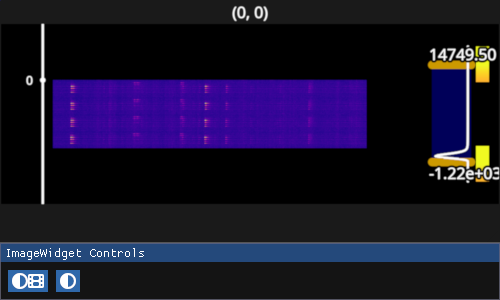

In [147]:
fpl.ImageWidget(past).show()

In [148]:
past.shape

(432, 1993)

In [149]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

In [150]:
PP_inv_sqrt = linalg.inv(linalg.sqrtm(PP))
FF_inv_sqrt = linalg.inv(linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

In [151]:
U, S, Vh = np.linalg.svd(K_bar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

Text(0.5, 1.0, 'right')

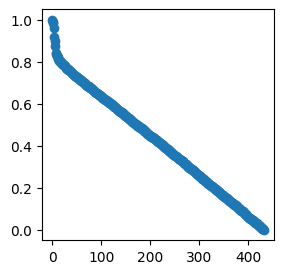

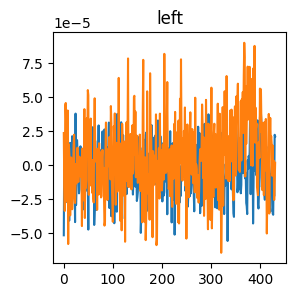

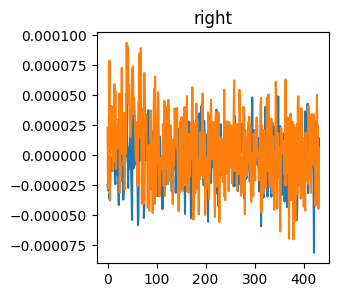

In [152]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec[:, :2])
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec[:, :2])
plt.title("right")

In [154]:
left_vec.shape

(432, 432)

In [165]:
left_vec[:, 1].shape

(432,)

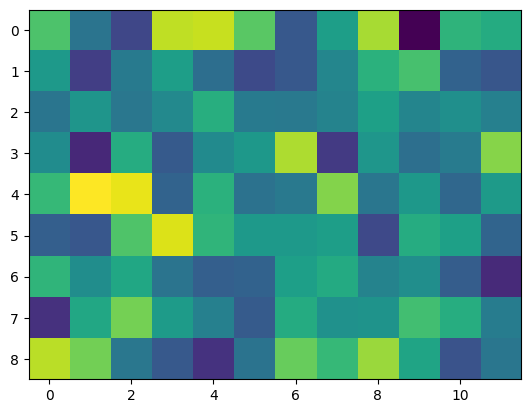

In [194]:
plt.imshow(unvec.transform(left_vec[:, 1][n_pixels * i:(i + 1) * n_pixels]))

In [195]:
A = left_vec[:, 1].reshape(n_pixels, lag)

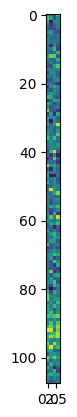

In [196]:
plt.imshow(A)

In [197]:
evals, evecs = np.linalg.eigh(A @ A.T)
evals = evals[::-1]
evecs = evecs[:, ::-1]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
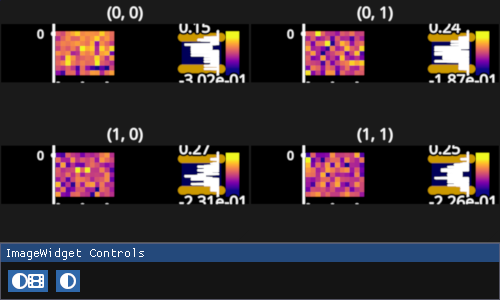

In [198]:
fpl.ImageWidget([unvec.transform(evecs[:, i]) for i in range(4)]).show()

In [199]:
evals, evecs = np.linalg.eigh(left_vec)
evals = evals[::-1]
evecs = evecs[:, ::-1]

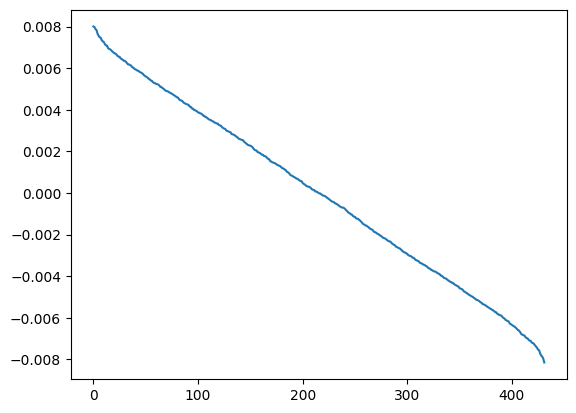

In [200]:
plt.plot(evals)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
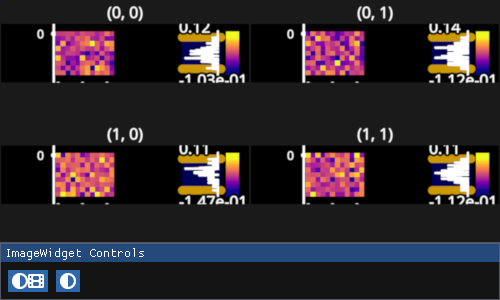

In [221]:
fpl.ImageWidget([unvec.transform(evecs[:, 4][n_pixels * i:(i + 1) * n_pixels]) for i in range(4)]).show()

In [201]:
fpl.ImageWidget([unvec.transform(evecs[:, i]) for i in range(4)]).show()

ValueError: cannot reshape array of size 432 into shape (9,12)

In [225]:
proj_left[:4].shape

(4, 1993)

RFBOutputContext()

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
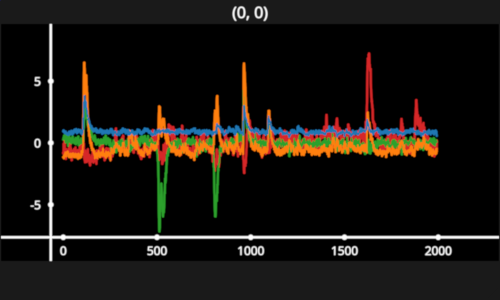

In [306]:
fig_p = fpl.Figure()
fig_proj = fpl.Figure()

fig_proj[0, 0].add_line_collection(proj_right[:4], cmap="tab10")

fig_proj.show(maintain_aspect=False)

In [307]:
proj_left[1].shape

(1993,)

In [308]:
left_vec.shape

(432, 432)

In [309]:
proj_left[1]

array([-1.11225879, -1.19286308, -1.08652938, ..., -0.4210008 ,
       -0.5972011 , -0.68567626])

In [310]:
left_vec.T[1].shape

(432,)

In [311]:
past.shape

(432, 1993)

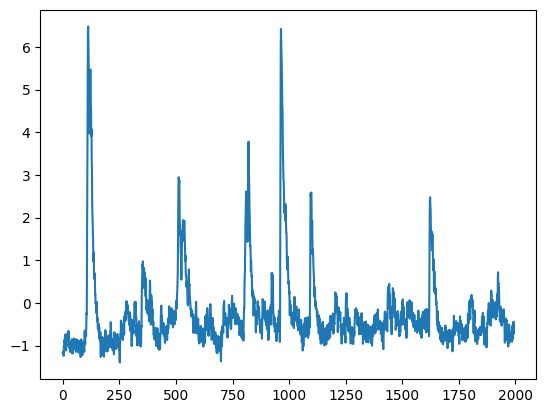

In [312]:
plt.plot(right_vec.T[1] @ future)

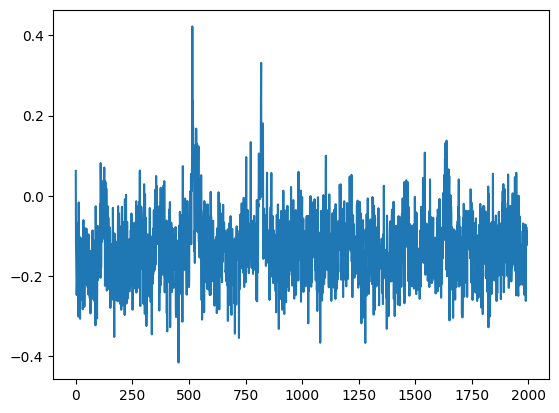

In [313]:
plt.plot(left_vec.T[1][n_pixels:n_pixels * 2] @ past[n_pixels:n_pixels * 2])

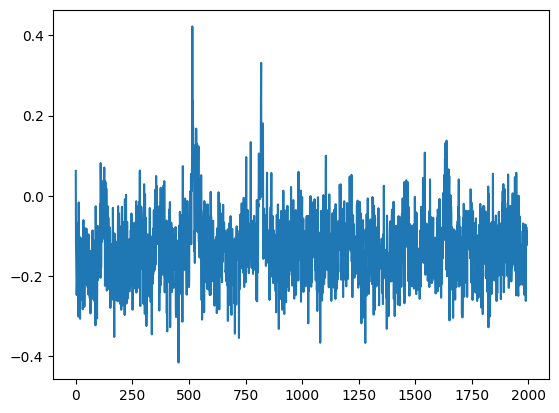

In [314]:
plt.plot(left_vec.T[1][n_pixels:n_pixels * 2] @ past[n_pixels:n_pixels * 2])

In [315]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag)]

In [316]:
s_ix = 2

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
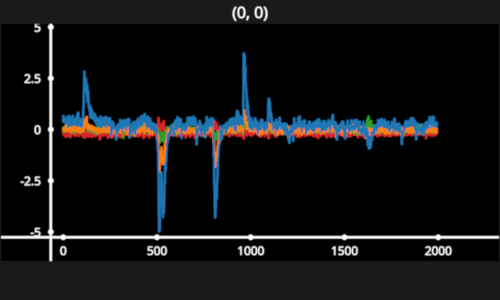

In [317]:
fig = fpl.Figure()

fig[0, 0].add_line_collection([right_vec.T[s_ix][lag_slices[i]] @ future[lag_slices[i]] for i in range(4)], cmap="tab10")

fig.show(maintain_aspect=False)

In [319]:
right_vec.T[1][lag_slices[0]].max()

9.360904337971565e-05

In [320]:
right_vec.T[1][lag_slices[0]].min()

-4.8140828784835814e-05

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
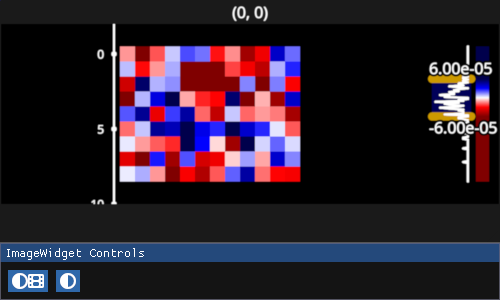

In [323]:
fpl.ImageWidget(unvec.transform(right_vec.T[s_ix][lag_slices[0]]), graphic_kwargs={"vmin": -6e-5, "vmax": 6e-5}, cmap="seismic_r").show()

In [297]:
u, s, v = np.linalg.svd(left_vec.T[s_ix].reshape(n_pixels, lag), full_matrices=False)

In [298]:
u.shape

(108, 4)

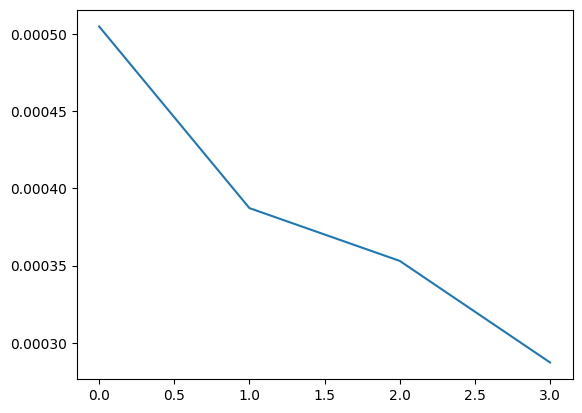

In [299]:
plt.plot(s)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
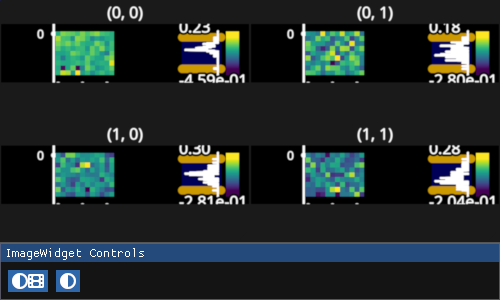

In [305]:
fpl.ImageWidget([unvec.transform(u[:, i]) for i in range(4)], cmap="viridis").show()

<Axes: >

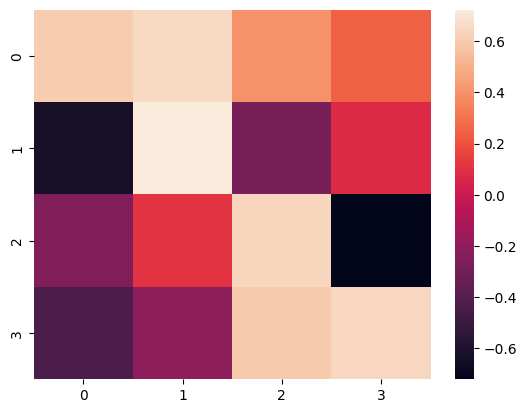

In [324]:
sns.heatmap(v)

In [ ]:
fpl.ImageWidget(unvec.transform(left_vec.T[1][lag_slices[3]]), graphic_kwargs={"vmin": -5e-5, "vmax": 5e-5}, cmap="bwr").show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
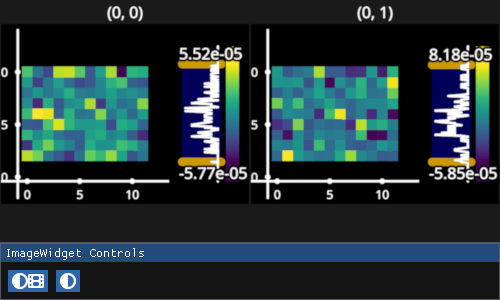

In [245]:
fpl.ImageWidget(
    [
        unvec.transform(left_vec.T[1][:n_pixels]),
        unvec.transform(left_vec.T[1][n_pixels:n_pixels * 2]),
    ],
    cmap="viridis",
).show()

In [ ]:
proj_left = left_vec.T @ past